In [2]:
import sys
import os
import json
import random
import matplotlib.pyplot as plt
from IPython.display import clear_output

import geopandas as gpd


sys.path.append('../')
import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING


In [3]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [22]:
_id = 'amxod7tf'


In [23]:


model_dir = os.path.join('../models_trained', _id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


    


In [27]:
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [29]:
x,y = next(iter(val_dl))

In [30]:
def plot_images(data, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])



    fig.tight_layout()
    plt.show()
    
def plot_images_with_tmf(data, tmf, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images+1, figsize=(16, 16))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

    ax[n_images].imshow(tmf.permute(1, 2, 0).numpy())
    ax[n_images].set_xticks([])
    ax[n_images].set_yticks([])
    
    fig.tight_layout()
    plt.show()
    



In [31]:
#df = train_dataset.img_labels

#df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])

In [42]:
dataset.img_labels

,driver,sampleid,dataset,country,geometry,block_id,split
0,coffee,190000083,manual_annotation.csv,Costa Rica,POINT (-84.25407 10.14892),92.0,val
1,coffee,190000084,manual_annotation.csv,Costa Rica,POINT (-84.37103 10.14003),92.0,val
2,coffee,190000085,manual_annotation.csv,Costa Rica,POINT (-84.38558 10.13114),92.0,val
3,coffee,190000086,manual_annotation.csv,Costa Rica,POINT (-84.32467 10.11335),92.0,val
4,coffee,190000087,manual_annotation.csv,Costa Rica,POINT (-84.40768 10.05999),92.0,val
...,...,...,...,...,...,...,...
5072,forest plantation,10655614,mapbiomas.csv,Brazil,POINT (-42.75639 -19.48473),33.0,val
5073,forest plantation,10655563,mapbiomas.csv,Brazil,POINT (-42.41844 -19.46694),33.0,val
5074,forest plantation,10656797,mapbiomas.csv,Brazil,POINT (-43.34335 -19.97386),33.0,val
5075,forest plantation,10653072,mapbiomas.csv,Brazil,POINT (-42.43623 -18.53314),33.0,val


In [47]:
xx = gpd.read_file('../data/tmp/preds.gpkg')

In [50]:
xx.loc[xx.country == 'Ethiopia'].loc[xx['driver'] == 'coffee']

,driver,sampleid,dataset,country,block_id,split,preds,correct,geometry
42,coffee,190000197,manual_annotation.csv,Ethiopia,154.0,4,forest regrowth,False,POINT (35.33212 6.96103)
43,coffee,190000198,manual_annotation.csv,Ethiopia,154.0,4,forest regrowth,False,POINT (35.33212 6.95214)
44,coffee,190000199,manual_annotation.csv,Ethiopia,154.0,4,coffee,True,POINT (35.34101 6.95214)
45,coffee,190000200,manual_annotation.csv,Ethiopia,154.0,4,forest regrowth,False,POINT (35.34990 6.95214)
46,coffee,190000201,manual_annotation.csv,Ethiopia,154.0,4,forest regrowth,False,POINT (35.33266 6.94325)
...,...,...,...,...,...,...,...,...,...
106,coffee,190000261,manual_annotation.csv,Ethiopia,154.0,4,coffee,True,POINT (35.46309 6.87210)
107,coffee,190000262,manual_annotation.csv,Ethiopia,154.0,4,coffee,True,POINT (35.32996 6.86321)
108,coffee,190000263,manual_annotation.csv,Ethiopia,154.0,4,coffee,True,POINT (35.34748 6.86321)
109,coffee,190000264,manual_annotation.csv,Ethiopia,154.0,4,coffee,True,POINT (35.44045 6.86321)


'forest regrowth'

driver                                            coffee
sampleid                                       190000251
dataset                            manual_annotation.csv
country                                         Ethiopia
geometry    POINT (35.469560345379854 6.880993470519291)
block_id                                           154.0
split                                                val
Name: 96, dtype: object
PREDICTION:  coffee
coffee


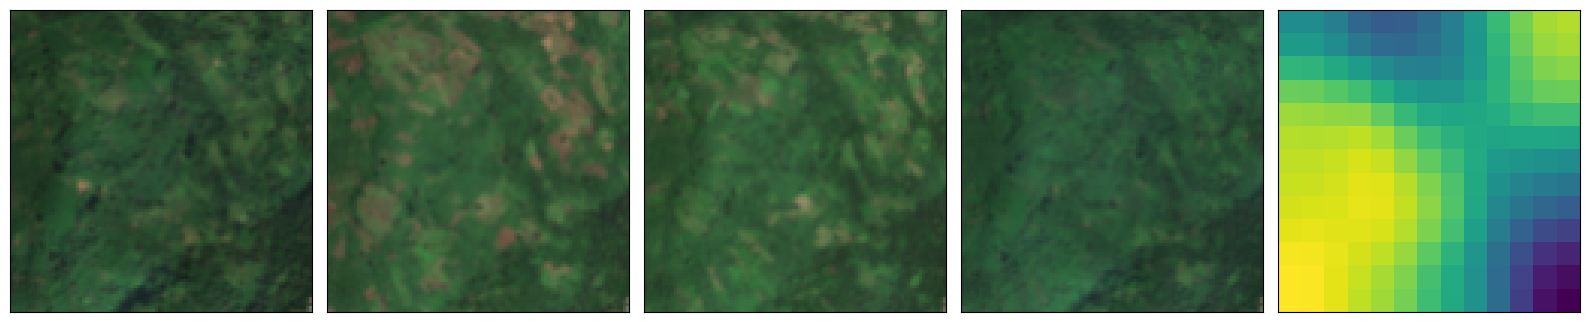

KeyboardInterrupt: Interrupted by user

In [57]:
for _i, row in val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.country == 'Ethiopia'].iterrows():
    i = row.name
    print(val_dl.dataset.img_labels.iloc[i])
    print('PREDICTION: ', xx.loc[xx.sampleid == row.sampleid].preds.values[0])
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 

    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

0

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


80084343
forest plantation


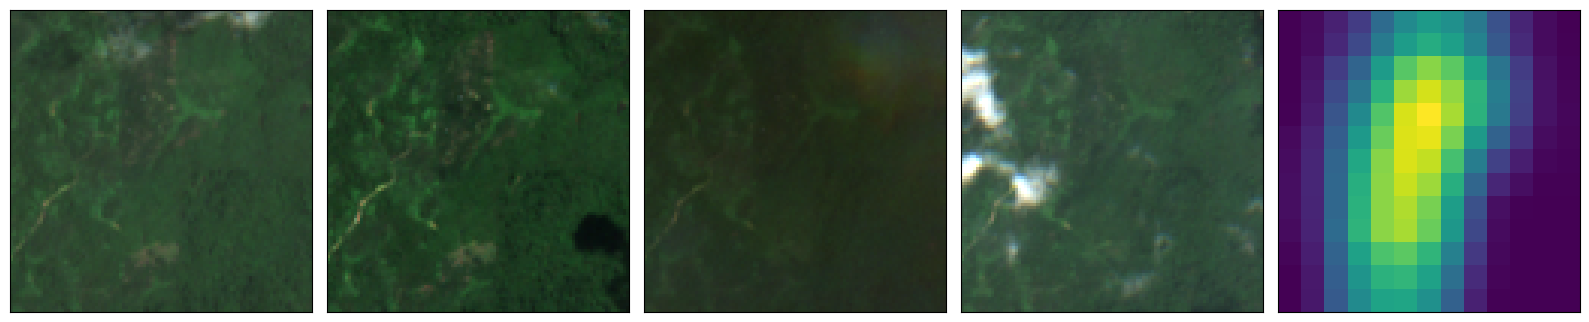

KeyboardInterrupt: Interrupted by user

In [21]:
dataset = val_dl.dataset

while True:

    i = random.randint(0,len(dataset.img_labels))
    #if not train_dataset.img_labels.iloc[i].driver == 'shifting agriculture':
    #    continue
    
    
    print(dataset.img_labels.iloc[i].sampleid)
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 

    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

    
    
    
    

In [ ]:
sampleids = [
2040330, #forest plant. looks like palm oil
    5000927, #forest plant. looks like palm oil
    8118421,  #forest plant. looks like palm oil
]

In [21]:
train_dataset.img_labels.loc[train_dataset.img_labels.sampleid == 5002879]

,geometry,driver,sampleid,split
7438,POINT (105.97349049958846 14.335897554805385),shifting agriculture,5002879,train


## Visualize time series with TMF